# 🐍 Clase 43 v2 — La neurona aprende sola

**Curso:** 3ro medio  |  **Duración:** 80 min  |  **Plataforma:** Google Colab

---

## 🎯 Objetivo de la clase

Crear, entrenar y evaluar una neurona con la misma receta del árbol y comparar ambos resultados con sorpresa.

## 🔎 ¿Por qué lo veremos?

> Las redes que reconocen voz o rostros están hechas de millones de estas neuronas que ponderan datos; hoy creamos una sola y vemos si le gana al árbol en los datos del wifi.

---

**Lo que ya sabes:** la receta de la N°42 y la N°42b (`crear → fit → predict → accuracy_score`) y cómo pasar una tabla a listas.

**Lo que aprenderás hoy:** qué es una neurona, cómo crearla con la misma receta del árbol, mirar los pesos que la computadora ajusta sola y comparar los dos modelos con los mismos datos. Se ejecuta **de arriba hacia abajo**.

## 🔧 Ejecuta esta celda primero

Los `import` raros van **SIEMPRE en la primera celda, ejecutada primero**: así no tienes que escribir `from sklearn... import ...` cada vez. Hoy traen el árbol (`DecisionTreeClassifier`), la neurona (`MLPClassifier`) y `accuracy_score`.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

Ahora ejecuta esta segunda celda (deja listos los verificadores automáticos; no hace falta entenderla ni editarla).

In [ ]:
#@title 🔧 Verificador automático — ejecútala después de la celda de los import (no la edites)
_ETQ_TRAIN = [1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1]
_ETQ_TEST = [0, 1, 1, 0]
_PRED = [0, 0, 1, 0]
_ACC_NEURONA = 0.75
_ACC_ARBOL = 1.0
_E0A = [1]
_E1 = [0.25, 0.25]
_E2 = [[0.875, 0.75, 0.875, 0.875, 0.5], [0.75, 0.75, 0.75, 0.75, 0.5]]


def _es_neurona(m):
    return isinstance(m, MLPClassifier) and tuple(m.hidden_layer_sizes) == () and m.max_iter == 2000 and m.random_state == 0


def _es_arbol(m):
    return isinstance(m, DecisionTreeClassifier) and m.max_depth == 3 and m.random_state == 0


def _igual(a, b):
    return a is not None and abs(float(a) - b) < 1e-9


def _datos_ok():
    g = globals()
    for n in ("entradas_train", "etiquetas_train", "entradas_test", "etiquetas_test"):
        if g.get(n) is None:
            print("⏳ Falta ejecutar la celda de los datos (las 4 listas).")
            return False
    return True


def check_icn():
    g = globals()
    if not _datos_ok():
        return
    m = g.get("modelo")
    if m is None:
        print("⏳ Falta crear la neurona y guardarla en una variable llamada modelo.")
        return
    if not isinstance(m, MLPClassifier):
        print("⚠️ modelo no es una neurona (MLPClassifier).")
        print("   Pista: la línea que crea el modelo es lo único que cambia respecto del árbol.")
        return
    if not _es_neurona(m):
        print("⚠️ Tu neurona no tiene los argumentos pedidos.")
        print("   Pista: hidden_layer_sizes=() (una sola neurona), max_iter=2000 y random_state=0.")
        return
    if not hasattr(m, "coefs_"):
        print("⏳ La neurona todavía no aprendió. Falta modelo.fit(entradas_train, etiquetas_train).")
        return
    p = g.get("predicciones")
    if p is None:
        print("⏳ Falta guardar en predicciones lo que predice la neurona para entradas_test.")
        return
    if [int(v) for v in p] != _PRED:
        print("⚠️ Tus predicciones no son las esperadas.")
        print("   Pista: entrena con train y predice con entradas_test, no con entradas_train.")
        return
    print("✅ La neurona aprendió y sus predicciones son las esperadas.")
    ex = g.get("exactitud")
    if ex is None:
        print("⏳ Falta calcular el accuracy de la neurona y guardarlo en una variable llamada exactitud.")
    elif _igual(ex, _ACC_NEURONA):
        print("✅ Tu accuracy de la neurona es el esperado.")
    else:
        print("⚠️ Tu accuracy de la neurona no coincide con el esperado.")
        print("   Pista: accuracy_score(etiquetas_test, predicciones): primero las reales, después las predichas.")


def check_comparar():
    g = globals()
    check_icn()
    ea = g.get("exactitud_arbol")
    if ea is None:
        print("⏳ Falta calcular el accuracy del árbol y guardarlo en exactitud_arbol.")
    elif _igual(ea, _ACC_ARBOL):
        print("✅ Tu accuracy del árbol es el esperado.")
        print("   Y ahora: ¿cuál de los dos usarían, y por qué?")
    else:
        print("⚠️ Tu accuracy del árbol no coincide con el esperado.")
        print("   Pista: usa predicciones_arbol (las del árbol) con etiquetas_test.")


def check_guiada():
    g = globals()
    if not _datos_ok():
        return
    ma, mn = g.get("modelo_arbol"), g.get("modelo_neurona")
    if ma is None or mn is None:
        print("⏳ Faltan los dos modelos: modelo_arbol y modelo_neurona.")
        return
    if not _es_arbol(ma):
        print("⚠️ modelo_arbol debe ser un árbol de profundidad máxima 3 y semilla 0.")
        return
    if not _es_neurona(mn):
        print("⚠️ modelo_neurona debe ser la neurona pedida (hidden_layer_sizes=(), max_iter=2000, random_state=0).")
        return
    if not hasattr(ma, "tree_") or not hasattr(mn, "coefs_"):
        print("⏳ Falta entrenar los dos modelos con fit(entradas_train, etiquetas_train).")
        return
    ea, en = g.get("exactitud_arbol"), g.get("exactitud_neurona")
    if ea is None or en is None:
        print("⏳ Faltan los accuracy: guárdalos en exactitud_arbol y exactitud_neurona.")
        return
    if not _igual(ea, _ACC_ARBOL):
        print("⚠️ El accuracy del árbol no es el esperado.")
        print("   Pista: predice con entradas_test y compara con etiquetas_test.")
    elif not _igual(en, _ACC_NEURONA):
        print("⚠️ El accuracy de la neurona no es el esperado.")
        print("   Pista: misma receta que el árbol; solo cambia la línea que crea el modelo.")
    else:
        print("✅ Tus dos modelos y sus accuracy son los esperados.")
        print("   Falta tu decisión escrita en un comentario: ¿cuál usarías y por qué? ¿Alcanzan 4 filas de prueba?")


def check_ej0a():
    p, m = globals().get("prediccion"), globals().get("modelo")
    if p is None or m is None:
        print("⏳ Falta guardar la predicción en una variable llamada prediccion.")
    elif [int(v) for v in p] != _E0A:
        print("⚠️ Tu predicción no corresponde a la fila nueva (88, 17, 4).")
        print("   Pista: una sola fila nueva va dentro de otra lista: [[...]].")
    else:
        print("✅ Predijiste la fila nueva con la forma correcta.")


def check_ej1():
    g = globals()
    ea, en = g.get("exactitud_arbol_otro"), g.get("exactitud_neurona_otro")
    if ea is None or en is None:
        print("⏳ Faltan exactitud_arbol_otro y exactitud_neurona_otro.")
    elif not _igual(ea, _E1[0]):
        print("⚠️ El accuracy del árbol con las otras columnas no es el esperado.")
        print("   Pista: entrena con entradas_train_otro y predice con entradas_test_otro.")
    elif not _igual(en, _E1[1]):
        print("⚠️ El accuracy de la neurona con las otras columnas no es el esperado.")
        print("   Pista: misma receta, solo cambia la línea que crea el modelo.")
    else:
        print("✅ Tus dos accuracy son los esperados. Compáralos con los de las columnas de la clase.")


def check_ej2():
    g = globals()
    tr, te = g.get("exactitudes_train"), g.get("exactitudes_test")
    if not tr or not te:
        print("⏳ Faltan las listas exactitudes_train y exactitudes_test.")
    elif len(tr) != 5 or len(te) != 5:
        print("⚠️ Cada lista debe tener 5 valores, uno por semilla (0, 1, 2, 3 y 4).")
    elif any(abs(float(a) - b) > 1e-9 for a, b in zip(tr, _E2[0])) or any(abs(float(a) - b) > 1e-9 for a, b in zip(te, _E2[1])):
        print("⚠️ Alguno de tus valores no coincide con el esperado.")
        print("   Pista: en cada vuelta crea la neurona con random_state=semilla, entrénala con train y mide train y test.")
    else:
        print("✅ Tus resultados son los esperados. ¿Cambian con la semilla? ¿Qué dice eso de confiar en una sola?")


print("Verificador listo ✅")

---

## 1️⃣ Haz Ahora

El encargado de informática del liceo sigue con su problema: **el cuaderno tenía 6 columnas, pero nos pide trabajar con estas 3**, las mismas de ayer:

- `dispositivos_conectados`: cuántos aparatos hay conectados al wifi
- `estudiantes_viendo_video`: cuántos estudiantes están viendo videos
- `horas_desde_reinicio`: cuántas horas lleva el router sin reiniciarse

1. Para saber si el wifi se cae, no todas las columnas pesan igual. Si tuvieran que ponerle una **importancia de 0 a 10** a cada una de estas 3 columnas, ¿qué nota le pondrían a cada una y por qué?
2. Ayer el árbol acertó los 4 días de prueba: ¿qué porcentaje de aciertos es eso?
3. Con 4 filas de prueba, ¿cuántos puntos porcentuales vale cada fila?
4. Si un modelo tuviera una precisión de 0,75 con esas 4 filas, ¿cuántas filas acertó?

Sabiendo que programamos, el encargado quiere probar un modelo nuevo — pero antes quiere que tengamos clara la lógica.

**Mis respuestas:**

1. 
2. 
3. 
4. 

---

### 🔁 Ayer → 🔀 Hoy → ➡️ La próxima clase

| | Qué hacemos |
|---|---|
| 🔁 **Ayer** | El árbol aprendió solo una cadena de preguntas sí/no con las listas que tipeamos. |
| 🔀 **Hoy es distinto** | Los mismos datos, otro modelo: una **neurona** que *pondera* cada columna (le da más o menos importancia). |
| ➡️ **La próxima clase (lunes 16)** | Mini-LLM: cómo una IA de lenguaje predice la siguiente palabra. |

| | Árbol | Neurona |
|---|---|---|
| Cómo decide | Cadena de preguntas sí/no | Suma de datos × importancia |
| Quién lo arma | La computadora, con `fit` | La computadora, con `fit` |
| La receta | crear → `fit` → `predict` → `accuracy_score` | **la misma** |

---

## 2️⃣ Introducción al Contenido Nuevo

Hoy **no tipeamos los datos**: las listas ya vienen escritas (lo hiciste a mano en la N°42b). Cada concepto usa lo anterior, así que **ejecuta las celdas en orden**.

### 💡 1. Datos listos

Son los mismos 20 días del wifi: las **primeras 16 filas** para que la computadora **aprenda** (`train`) y las **últimas 4** para **probarla** (`test`). La etiqueta es `1` = el wifi se cayó, `0` = aguantó.

> **Idea clave:** las listas `entradas_train`, `etiquetas_train`, `entradas_test` y `etiquetas_test` son el material con el que aprende y se prueba cualquier modelo.

▶️ **Solo ejecuta** la celda.

In [ ]:
entradas_train = [[71, 0, 20],
    [62, 2, 12],
    [79, 2, 2],
    [73, 0, 15],
    [102, 9, 22],
    [103, 20, 1],
    [101, 17, 12],
    [59, 22, 23],
    [77, 7, 22],
    [50, 0, 14],
    [76, 0, 14],
    [69, 0, 7],
    [59, 0, 19],
    [115, 28, 22],
    [47, 2, 2],
    [78, 0, 16]]

etiquetas_train = [1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1]

entradas_test = [[51, 0, 16],
    [117, 0, 16],
    [75, 22, 2],
    [66, 0, 9]]

etiquetas_test = [0, 1, 1, 0]

### 💡 2. ¿Qué es una neurona?

Una **neurona** es el modelo más pequeño de una red neuronal. Recibe las 3 columnas, **pondera** cada una (le da más o menos importancia), las **suma** y **decide** 0 o 1. Esos números de importancia se llaman **pesos** y **no los escribimos nosotros: los ajusta sola la computadora al entrenar**.

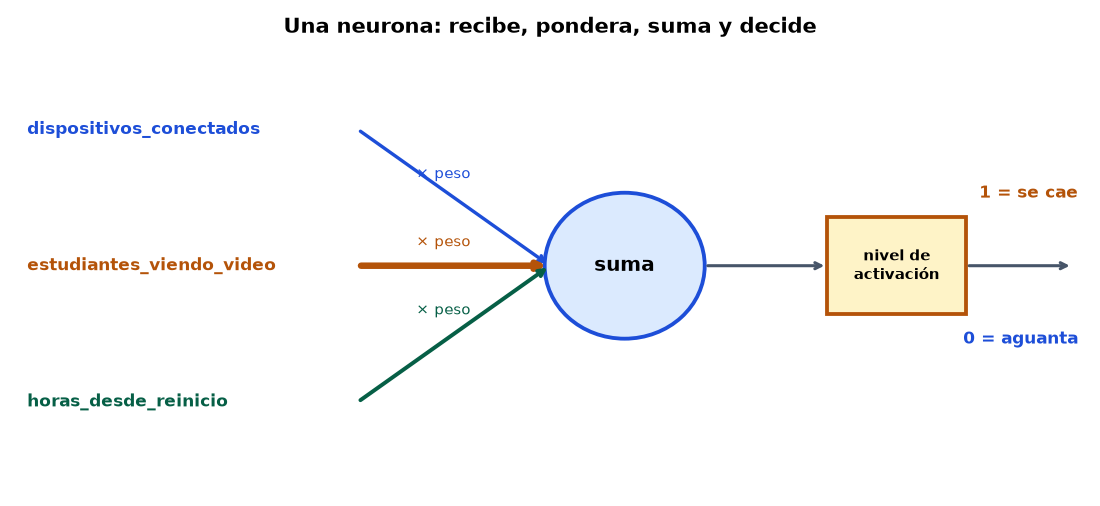

La flecha más gruesa es el dato con más peso. Después de sumar, la neurona calcula su **nivel de activación**: un número entre **0 y 1**. Si pasa de **0,5**, decide **1** (se cae); si no, decide **0** (aguanta).

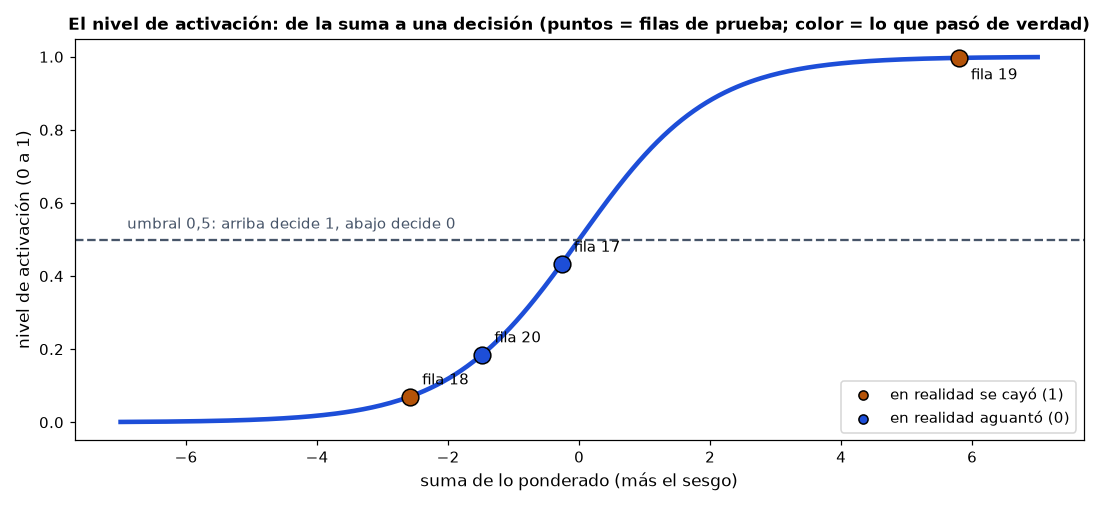

Cada punto es una de las 4 filas de prueba: mientras más a la derecha, mayor la suma y más se acerca el nivel de activación a 1.

> **Idea clave:** una neurona recibe datos, pondera cada uno (peso), suma, calcula su nivel de activación (de 0 a 1) y decide: más de 0,5 → 1; si no → 0. Los pesos los ajusta sola la computadora.

### 💡 3. La receta, cambiando una sola línea

Es la receta de ayer: **crear → `fit` → `predict` → `accuracy_score`**. Lo único que cambia es la línea que crea el modelo. La neurona se crea así: `MLPClassifier(hidden_layer_sizes=(), max_iter=2000, random_state=0)`.

> **Idea clave:** para usar otro modelo solo cambia la línea que lo crea; `fit`, `predict` y `accuracy_score` quedan igual.

✍️ **Escríbelo tú:** crea la neurona en `modelo`, entrénala con `train`, guarda en `predicciones` lo que predice para `entradas_test` y calcula su accuracy en `exactitud`.

In [ ]:
# Ayer (árbol):  modelo = DecisionTreeClassifier(max_depth=3, random_state=0)
# Hoy (neurona): escribe la línea que crea la neurona
modelo = None   # ← reemplaza None

# Entrena con train, predice el test y calcula el accuracy
# Muestra las predicciones y el accuracy con una etiqueta clara

<details><summary>❓ ¿Qué significa <code>hidden_layer_sizes=()</code>?</summary>

Es el argumento que dice cuántas neuronas más se agregan en medio. Con `()` no hay ninguna: es **una sola neurona**. Cuántas poner se decide por prueba y error (hoy hay sistemas que automatizan esa búsqueda); nosotros seguimos con una sola.

</details>

#### 🔍 Revisa tu trabajo

Ejecuta la celda para comprobar tu neurona.

In [ ]:
check_icn()

### 💡 4. Abrir la caja: los pesos

Después de `fit`, la neurona guarda los **pesos** que la computadora ajustó sola: `modelo.coefs_` (uno por columna, en el orden de las listas) y el **sesgo** (un pequeño ajuste extra): `modelo.intercepts_`.

> **Idea clave:** `coefs_` e `intercepts_` son los pesos que la computadora ajustó sola; existen, pero no los leemos como verdad absoluta.

✍️ **Escríbelo tú:** muestra los pesos y el sesgo de tu `modelo`, cada uno con una etiqueta clara.

In [ ]:
# Muestra los pesos (coefs_) y el sesgo (intercepts_)

🎲 **La semilla importa:** `random_state` es el número que fija el **punto de partida aleatorio** del entrenamiento. Con otra semilla los pesos (y a veces el accuracy) **salen distintos**. Cambia `semilla` a 1, ejecuta, y vuelve a 0:

> **Siempre dejamos `random_state=0`** en las pruebas para que todos obtengamos lo mismo.

*(Los números también pueden variar por otras razones técnicas, por ejemplo cómo termina de procesar el entrenamiento; no las veremos en este curso. Y los pesos no dicen por sí solos qué columna «es la importante»: quédate con que **existen y los ajusta la computadora**.)*

In [ ]:
semilla = 0   # cambia este número (0, 1, 2…) y ejecuta de nuevo
modelo_semilla = MLPClassifier(hidden_layer_sizes=(), max_iter=2000, random_state=semilla)
modelo_semilla.fit(entradas_train, etiquetas_train)
print("Semilla:", semilla)
print("Pesos:", modelo_semilla.coefs_)
print("Accuracy en train:", accuracy_score(etiquetas_train, modelo_semilla.predict(entradas_train)))
print("Accuracy en test:", accuracy_score(etiquetas_test, modelo_semilla.predict(entradas_test)))

#### ✅ Verificamos lo aprendido

El colega le pregunta a dos personas del curso:

- ¿Por qué cambian los pesos si usamos otra semilla?
- ¿Los pesos los escribimos nosotros o los ajustó la computadora?

### 💡 5. Revisar y comparar

Al revisar hacemos dos cosas:

1. **Leer el resultado:** mira las `predicciones` de la neurona junto a las `etiquetas_test`: ¿en qué fila falló?
2. **Comparar la precisión:** el `accuracy_score` de la neurona frente al del árbol de ayer, **con los mismos datos**. Con 4 filas de prueba, cada fila vale 25 %.

> **Idea clave:** para comparar dos modelos se usan los mismos datos y el mismo `accuracy_score`; con 4 filas de prueba cada fila vale 25 %.

✍️ **Escríbelo tú:** muestra las etiquetas reales y las predicciones de la neurona; calcula el accuracy del árbol en `exactitud_arbol` y muestra ambos accuracy con etiqueta.

In [ ]:
# El árbol de ayer, con los mismos datos (ya escrito)
arbol = DecisionTreeClassifier(max_depth=3, random_state=0)
arbol.fit(entradas_train, etiquetas_train)
predicciones_arbol = arbol.predict(entradas_test)

# 1. Leer el resultado: etiquetas reales y predicciones de la neurona

# 2. Comparar la precisión: exactitud_arbol y exactitud (la de la neurona)

In [ ]:
check_comparar()

🤔 **Para pensar:** ¿cuál de los dos usarían, y por qué? ¿Qué cambia si la diferencia es de una sola fila?

### 📌 Entonces, ¿qué debe quedar claro en tu cuaderno?

| Concepto | Cómo se escribe |
|---|---|
| Los `import` | siempre en la primera celda, ejecutada primero |
| Neurona | recibe datos, pondera (pesos), suma, calcula su nivel de activación (0 a 1) y decide: más de 0,5 → 1 |
| Crearla | `modelo = MLPClassifier(hidden_layer_sizes=(), max_iter=2000, random_state=0)` |
| La receta | `fit` → `predict` → `accuracy_score`: igual que el árbol |
| Los pesos | `modelo.coefs_` e `modelo.intercepts_`: los ajustó sola la computadora |
| `random_state` | fija el punto de partida; en las pruebas siempre `0` |
| Comparar | mismos datos, mismo `accuracy_score`; con 4 filas cada fila vale 25 % |

#### 🎞️ Resumen animado

Para repasar cada concepto con animaciones, mira las slides: [https://clases-ia-mario-bertero.vercel.app/clase-43-v2/](https://clases-ia-mario-bertero.vercel.app/clase-43-v2/)

#### ⚠️ Errores típicos a evitar

| Error | Qué ocurre | Cómo corregirlo |
|---|---|---|
| No ejecutar la celda de los `import` | `NameError: name 'MLPClassifier' is not defined` | Ejecutar siempre primero la celda de los `import` |
| Cambiar `random_state` y creer que es otro modelo | Los pesos y a veces el accuracy cambian | Dejar `random_state=0` en las pruebas |
| Leer los pesos como verdad absoluta | Concluir qué columna «importa» con una sola corrida | Recordar que existen y los ajusta la computadora |
| Concluir con solo 4 filas de prueba | Se confía en una diferencia de una fila | Cada fila vale 25 %: probar con más filas |

---

## 3️⃣ Práctica Guiada

Este es **el ejercicio de la clase**: lo hacemos todos y al final revisamos uno entre todos.

### 🎯 El encargado quiere decidir con qué modelo quedarse

El encargado de informática del liceo tiene los mismos 20 días de wifi y dos modelos que probar: el **árbol** de ayer y la **neurona** de hoy. Las listas ya están escritas. Quiere ver los dos accuracy y que le cuentes, con tus propios números, cuál usarías. Antes de decidir, le preocupa que la prueba tenga muy pocas filas.

**El programa debe:**

- **Crear** el árbol (profundidad máxima 3, semilla 0) en `modelo_arbol` y la neurona en `modelo_neurona`, y **entrenar** los dos con `train`.
- **Predecir** el test con cada uno y **calcular** sus accuracy en `exactitud_arbol` y `exactitud_neurona`.
- **Mostrar** ambos accuracy con una etiqueta clara.
- **Escribir**, en un comentario, 2 líneas: cuál usarías y por qué (con tus números), y por qué 4 filas de prueba dan poca seguridad.

<details><summary>💡 Pista 1 — la misma receta</summary>

Los dos modelos se entrenan y se evalúan igual; solo cambia la línea que crea cada uno.

</details>

<details><summary>💡 Pista 2 — cada fila vale 25 %</summary>

Con 4 filas de prueba, una fila de diferencia mueve el accuracy 0,25 puntos: piensa si eso alcanza para estar seguros.

</details>

📤 <em>El programa imprime:</em>

<pre>Accuracy del árbol: 1.0
Accuracy de la neurona: 0.75</pre>

In [ ]:
# Tu programa

# ── Escribe tu programa desde aquí ──

In [ ]:
check_guiada()

---

## 🎫 Ticket de Salida

Las preguntas **se proyectan en la tele**: no están en este cuaderno. Mira cada pregunta y **decide tu respuesta en silencio**; cuando termine la última, abre el formulario, escribe tu nombre y marca tus alternativas.

👉 **Formulario del Ticket de Salida:** [https://forms.gle/sjRpbgmQzrpkEBsH9](https://forms.gle/sjRpbgmQzrpkEBsH9)

En «Tema de la clase de hoy» escribe: **La neurona aprende sola**.

---

## 🎯 Cierre

**Objetivo de la clase**

Crear, entrenar y evaluar una neurona con la misma receta del árbol y comparar ambos resultados con sorpresa.

---

**Reflexiona antes de irte** (las comentamos a viva voz):

1. ¿Qué tan seguro/a te sientes creando, entrenando y evaluando una neurona, donde 1 es "no entendí nada" y 5 es "puedo explicárselo a otro"?

2. ¿Qué te sorprendió hoy de la neurona y por qué?

3. ¿Dónde crees que se usan neuronas como esta fuera de la clase?

👀 **Lo que viene (lunes 16):** el mini-LLM: cómo una IA de lenguaje predice la siguiente palabra.

### 📝 Mis respuestas

*(haz doble click para editar y escribir tus respuestas)*

1. 

2. 

3. 

---

---

## 4️⃣ Ejercicios extra

Para seguir practicando en casa o si terminas antes. Cada uno trae pistas y un verificador. No tienen nota.

### 🎯 Ejercicio 0a — Práctica directa: predecir una fila nueva

La celda de abajo ya trae la neurona entrenada.

**El programa debe:**

- Preguntar a la neurona por **una sola** fila nueva: 88 dispositivos, 17 estudiantes viendo video y 4 horas desde el reinicio.
- Guardar la predicción en una variable llamada `prediccion` e imprimirla con una etiqueta.

📤 <em>El programa imprime:</em>

<pre>Predicción para la fila nueva (1 = se cae, 0 = aguanta): [1]</pre>

In [ ]:
# Tu solución del Ejercicio 0a
entradas_train = [[71, 0, 20],
    [62, 2, 12],
    [79, 2, 2],
    [73, 0, 15],
    [102, 9, 22],
    [103, 20, 1],
    [101, 17, 12],
    [59, 22, 23],
    [77, 7, 22],
    [50, 0, 14],
    [76, 0, 14],
    [69, 0, 7],
    [59, 0, 19],
    [115, 28, 22],
    [47, 2, 2],
    [78, 0, 16]]

etiquetas_train = [1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1]

entradas_test = [[51, 0, 16],
    [117, 0, 16],
    [75, 22, 2],
    [66, 0, 9]]

etiquetas_test = [0, 1, 1, 0]

modelo = MLPClassifier(hidden_layer_sizes=(), max_iter=2000, random_state=0)
modelo.fit(entradas_train, etiquetas_train)

# ── Escribe tu programa desde aquí ──

In [ ]:
check_ej0a()

### 🎯 Ejercicio 1 — ¿Y si el encargado usa otras columnas?

Un compañero propone usar otras tres columnas del cuaderno del encargado: `temperatura_sala`, `hora_del_bloque` y `dia_del_mes`. Las listas ya están escritas. Hay que entrenar los dos modelos con ellas y ver cómo les va frente a las columnas de la clase.

**El programa debe:**

- **Entrenar** un árbol (profundidad 3, semilla 0) y la neurona de hoy con `entradas_train_otro` y `etiquetas_train`.
- **Calcular** sus accuracy en `exactitud_arbol_otro` y `exactitud_neurona_otro` con `entradas_test_otro` y `etiquetas_test`, y **mostrarlos**.
- **Escribir**, en un comentario, si estas columnas funcionan mejor o peor que las de la clase y qué sospechas.

<details><summary>💡 Pista 1 — los datos</summary>

`entradas_train_otro` y `entradas_test_otro` reemplazan a las listas de la clase; las etiquetas son las mismas.

</details>

<details><summary>💡 Pista 2 — la receta</summary>

Es la misma receta de hoy; solo cambian las listas de entradas.

</details>

📤 <em>El programa imprime:</em>

<pre>Accuracy del árbol con las otras columnas: 0.25
Accuracy de la neurona con las otras columnas: 0.25</pre>

In [ ]:
# Tu solución del Ejercicio 1
entradas_train_otro = [[24, 8, 7],
    [29, 6, 23],
    [23, 1, 23],
    [19, 7, 20],
    [18, 6, 4],
    [23, 6, 31],
    [26, 5, 29],
    [30, 3, 6],
    [24, 4, 4],
    [30, 4, 27],
    [26, 6, 28],
    [24, 5, 18],
    [33, 7, 21],
    [20, 4, 26],
    [19, 6, 21],
    [29, 3, 31]]

entradas_test_otro = [[22, 5, 3],
    [30, 4, 5],
    [18, 8, 24],
    [27, 6, 5]]

# ── Escribe tu programa desde aquí ──

In [ ]:
check_ej1()

### 🎯 Ejercicio 2 — Desafío: ¿y si cambiamos la semilla?

El encargado desconfía: «si cambio el número de la semilla, ¿la neurona sigue acertando igual?». Hay que probar cinco semillas y mirar qué pasa tanto con los días que la neurona usó para aprender como con los de prueba.

**El programa debe:**

- **Entrenar** la neurona de hoy una vez por cada semilla de 0 a 4.
- **Guardar** el accuracy en `train` de cada una en `exactitudes_train` y el de `test` en `exactitudes_test`, y **mostrar** ambas listas.
- **Escribir**, en un comentario, si los resultados cambian y qué te dice eso sobre confiar en una sola corrida.

<details><summary>💡 Pista 1 — repetir cinco veces</summary>

Puedes recorrer las semillas con `for semilla in [0, 1, 2, 3, 4]:` y crear la neurona con `random_state=semilla`.

</details>

<details><summary>💡 Pista 2 — guardar cada resultado</summary>

Parte con una lista vacía y agrega cada accuracy con `.append(...)`.

</details>

📤 <em>El programa imprime:</em>

<pre>Accuracy en train por semilla: [0.875, 0.75, 0.875, 0.875, 0.5]
Accuracy en test por semilla:  [0.75, 0.75, 0.75, 0.75, 0.5]</pre>

In [ ]:
# Tu solución del Ejercicio 2

# ── Escribe tu programa desde aquí ──

In [ ]:
check_ej2()